<h3>Stacked Forecast SHAP Explanations</h3>

<p>This notebook explains the saved H1 and H2 stacked forecasts using the exact additive SHAP decomposition for a Ridge meta-learner. It loads each saved stack and only that horizon's held-out feature rows. It does not refit models, tune parameters, or rerun the final price forecasts.</p>

<p>For the linear Ridge combiner, the two base-model SHAP arrays are weighted by the fitted Ridge coefficients, and their expected values are combined with the Ridge intercept. This is exact for Ridge; it is not valid for a nonlinear meta-model.</p>

<h3>1. Colab Runtime and Drive Artifacts</h3>



In [1]:
import base64
import json
import os
from pathlib import Path
import subprocess
import sys

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REPO_URL = 'https://github.com/RAM-AS-RAP/ucs35-mudibo-ml.git'
REPO_BRANCH = 'feature/model-training'

if IN_COLAB:
    drive.mount('/content/drive')
    subprocess.check_call([
        sys.executable, '-m', 'pip', 'install', '-q',
        'pandas<3', 'numpy', 'scikit-learn', 'xgboost', 'shap', 'matplotlib',
        'joblib', 'python-dotenv',
    ])
    from dotenv import load_dotenv
    ENV_PATHS = [
        Path('/content/drive/MyDrive/capstone-data/.env'),
        Path('/content/drive/MyDrive/AgriSence/.env'),
        Path('/content/drive/MyDrive/.env'),
        Path('/content/.env'),
    ]
    for env_path in ENV_PATHS:
        if env_path.exists():
            load_dotenv(env_path, override=False)
    repo_dir = Path('/content/AgriSence_model_training')
    repo_candidates = [repo_dir]
else:
    repo_dir = None
    repo_candidates = [Path.cwd(), *Path.cwd().resolve().parents]

repo_root = next((
    path.resolve() for path in repo_candidates
    if (path / 'pyproject.toml').exists() and (path / 'src/agrisence').exists()
), None)
if repo_root is None and IN_COLAB:
    github_token = os.getenv('GITHUB_TOKEN') or os.getenv('GH_TOKEN')
    if not github_token:
        from google.colab import userdata
        for secret_name in ('GITHUB_TOKEN', 'GH_TOKEN'):
            try:
                github_token = userdata.get(secret_name)
            except Exception:
                continue
            if github_token:
                break
    if not github_token:
        raise RuntimeError('Private repository clone requires GITHUB_TOKEN or GH_TOKEN in Colab Secrets or Drive .env.')
    auth_header = base64.b64encode(f'x-access-token:{github_token}'.encode()).decode()
    subprocess.run([
        'git', '-c', f'http.https://github.com/.extraheader=AUTHORIZATION: basic {auth_header}',
        'clone', '-b', REPO_BRANCH, REPO_URL, str(repo_dir),
    ], check=True)
    del github_token, auth_header
    repo_root = repo_dir.resolve()
if repo_root is None:
    raise FileNotFoundError('Start this notebook from inside the AgriSence repository.')
if IN_COLAB:
    os.chdir(repo_root)
    load_dotenv(repo_root / '.env', override=False)

if IN_COLAB:
    current_branch = subprocess.run(
        ['git', '-C', str(repo_root), 'branch', '--show-current'],
        check=True, capture_output=True, text=True,
    ).stdout.strip()
    if current_branch != REPO_BRANCH:
        raise RuntimeError(f'Colab checkout is on {current_branch!r}; expected {REPO_BRANCH!r}.')
    tracked_changes = subprocess.run(
        ['git', '-C', str(repo_root), 'status', '--porcelain', '--untracked-files=no'],
        check=True, capture_output=True, text=True,
    ).stdout.strip()
    if tracked_changes:
        raise RuntimeError('Colab checkout has tracked edits. Preserve them before updating the repository.')
    github_token = os.getenv('GITHUB_TOKEN') or os.getenv('GH_TOKEN')
    if not github_token:
        from google.colab import userdata
        for secret_name in ('GITHUB_TOKEN', 'GH_TOKEN'):
            try:
                github_token = userdata.get(secret_name)
            except Exception:
                continue
            if github_token:
                break
    if not github_token:
        raise RuntimeError('Enable GITHUB_TOKEN or GH_TOKEN in Colab Secrets to update the private repository.')
    git_env = os.environ.copy()
    config_index = int(git_env.get('GIT_CONFIG_COUNT', '0'))
    git_env['GIT_CONFIG_COUNT'] = str(config_index + 1)
    git_env[f'GIT_CONFIG_KEY_{config_index}'] = 'http.https://github.com/.extraheader'
    git_env[f'GIT_CONFIG_VALUE_{config_index}'] = (
        'AUTHORIZATION: basic ' + base64.b64encode(f'x-access-token:{github_token}'.encode()).decode()
    )
    try:
        subprocess.run(
            ['git', '-C', str(repo_root), 'fetch', 'origin', REPO_BRANCH],
            env=git_env, check=True,
        )
        subprocess.run(
            ['git', '-C', str(repo_root), 'merge', '--ff-only', f'origin/{REPO_BRANCH}'],
            check=True,
        )
    finally:
        del github_token, git_env
    revision = subprocess.run(
        ['git', '-C', str(repo_root), 'rev-parse', '--short', 'HEAD'],
        check=True, capture_output=True, text=True,
    ).stdout.strip()
    print(f'Colab checkout updated: {REPO_BRANCH} at {revision}')

import importlib
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from IPython.display import display

sys.path.insert(0, str(repo_root / 'src'))
for module_name in list(sys.modules):
    if module_name == 'agrisence' or module_name.startswith('agrisence.'):
        del sys.modules[module_name]
importlib.invalidate_caches()
from agrisence.explainability.shap_explainer import (
    compute_stack_shap_values,
    shap_to_farmer_explanation,
)

if IN_COLAB:
    feature_dir = Path('/content/drive/MyDrive/capstone-data/feature_engineering')
    evaluation_dir = Path('/content/drive/MyDrive/capstone-data/final_evaluation')
    model_dir = Path('/content/drive/MyDrive/capstone-data/models')
    drive_shap_dir = Path('/content/drive/MyDrive/capstone-data/explainability')
else:
    artifact_dir = repo_root / 'results/artifacts'
    feature_dir = artifact_dir / 'feature_engineering'
    evaluation_dir = artifact_dir
    model_dir = artifact_dir / 'models'
    drive_shap_dir = None

shap_dir = repo_root / 'results/artifacts'
shap_dir.mkdir(parents=True, exist_ok=True)
if drive_shap_dir is not None:
    drive_shap_dir.mkdir(parents=True, exist_ok=True)

horizon_paths = {
    horizon: {
        'table': feature_dir / f'model_df_{horizon}.csv',
        'folds': feature_dir / f'folds_{horizon}.json',
        'predictions': evaluation_dir / f'test_predictions_{horizon}.csv',
        'manifest': evaluation_dir / f'evaluation_manifest_{horizon}.json',
        'model': model_dir / f'stacking_{horizon}.pkl',
    }
    for horizon in ('h1', 'h2')
}
missing_paths = [str(path) for config in horizon_paths.values() for path in config.values() if not path.exists()]
if missing_paths:
    raise FileNotFoundError(
        'Final evaluation artifacts are missing. Run the final evaluation first or confirm their Drive paths:\n'
        + '\n'.join(missing_paths)
    )
print(f'Repository: {repo_root}')
print(f'Feature and fold files: {feature_dir}')
print(f'Final model bundles: {model_dir}')
print(f'SHAP output directory: {shap_dir}')
if IN_COLAB:
    print(f'Drive SHAP output directory: {drive_shap_dir}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab checkout updated: feature/model-training at 4f1eb0e
Repository: /content/AgriSence_model_training
Feature and fold files: /content/drive/MyDrive/capstone-data/feature_engineering
Final model bundles: /content/drive/MyDrive/capstone-data/models
SHAP output directory: /content/AgriSence_model_training/results/artifacts
Drive SHAP output directory: /content/drive/MyDrive/capstone-data/explainability


<h3>2. Compute H1 and H2 Stacking Explanations</h3>




In [2]:
shap_results = {}
summary_tables = {}

for horizon in ('h1', 'h2'):
    paths = horizon_paths[horizon]
    models = joblib.load(paths['model'])
    if models.get('horizon') != horizon or not models.get('test_evaluated', False):
        raise ValueError(f'{horizon.upper()} bundle is not the saved final-evaluation model.')
    feature_cols = models['feature_cols']

    with paths['manifest'].open(encoding='utf-8') as manifest_file:
        manifest = json.load(manifest_file)
    if manifest.get('status') != 'completed; held-out test closed':
        raise ValueError(f'{horizon.upper()} final evaluation is not marked completed.')

    with paths['folds'].open(encoding='utf-8') as folds_file:
        folds = json.load(folds_file)
    table = pd.read_csv(paths['table'], parse_dates=['month', 'target_month'])
    if folds['table_row_position'] != list(range(len(table))):
        raise ValueError(f'{horizon.upper()} fold rows do not match the supervised table.')
    test_mask = np.asarray(folds['test_mask'])
    if test_mask.dtype != np.dtype(bool) or test_mask.shape != (len(table),):
        raise ValueError(f'{horizon.upper()} test mask is not aligned with the saved feature table.')

    test_df = table.loc[test_mask].copy()
    if len(test_df) != manifest['test_rows']:
        raise ValueError(f'{horizon.upper()} test row count does not match its final-evaluation manifest.')
    X_test = test_df[feature_cols].reset_index(drop=True)
    keys = ['month', 'market', 'commodity']
    test_keys = test_df[keys].reset_index(drop=True).copy()
    saved_predictions = pd.read_csv(paths['predictions'], parse_dates=['month'])
    saved_keys = saved_predictions[keys].reset_index(drop=True).copy()
    if not test_keys.equals(saved_keys):
        raise ValueError(f'{horizon.upper()} features are not aligned with the saved final predictions.')
    if 'stacking_pred' not in saved_predictions:
        raise ValueError(f'{horizon.upper()} final predictions do not contain the stacking output.')

    shap_result = compute_stack_shap_values(models, X_test)
    reconstructed_stack = shap_result['base_value'] + shap_result['shap_values'].sum(axis=1)
    np.testing.assert_allclose(
        reconstructed_stack,
        saved_predictions['stacking_pred'].to_numpy(dtype=float),
        rtol=1e-5,
        atol=1e-6,
        err_msg=f'{horizon.upper()} SHAP values do not reconstruct the saved stack forecasts.',
    )
    shap_results[horizon] = shap_result

    importance = pd.DataFrame({
        'feature': shap_result['feature_names'],
        'mean_abs_shap': np.abs(shap_result['shap_values']).mean(axis=0),
    }).sort_values('mean_abs_shap', ascending=False, kind='stable').reset_index(drop=True)
    importance.insert(0, 'horizon', horizon)
    summary_tables[horizon] = importance

    attribution_table = pd.DataFrame(shap_result['shap_values'], columns=shap_result['feature_names'])
    attribution_table.insert(0, 'base_value', shap_result['base_value'])
    for column in keys:
        attribution_table.insert(len(attribution_table.columns), column, test_keys[column].to_numpy())
    attribution_table.insert(0, 'horizon', horizon)

    for output_dir in (shap_dir, drive_shap_dir):
        if output_dir is not None:
            output_dir.mkdir(parents=True, exist_ok=True)
            attribution_table.to_csv(output_dir / f'shap_values_{horizon}.csv', index=False)
            importance.to_csv(output_dir / f'shap_summary_{horizon}.csv', index=False)

    shap.summary_plot(
        shap_result['shap_values'],
        X_test,
        plot_type='dot',
        max_display=len(feature_cols),
        plot_size=(8, 4.5),
        show=False,
    )
    plt.title(f'{horizon.upper()} stacked forecast SHAP summary')
    plt.tight_layout()
    plot_filename = f'shap_beeswarm_{horizon}.png'
    for output_dir in (shap_dir, drive_shap_dir):
        if output_dir is not None:
            plt.savefig(output_dir / plot_filename, dpi=200, bbox_inches='tight')
    plt.close()

    print(f'{horizon.upper()} mean absolute SHAP importance:')
    display(importance)

print(f'Saved per-row SHAP values, feature summaries, and plots under {shap_dir}')
if drive_shap_dir is not None:
    print(f'Mirrored SHAP artifacts to Google Drive: {drive_shap_dir}')

H1 mean absolute SHAP importance:


,horizon,feature,mean_abs_shap
0,h1,month_cos,0.016624
1,h1,year,0.010912
2,h1,log_ratio_3m,0.004143
3,h1,log_return_lag_2,0.002711
4,h1,log_ratio_12m,0.002688
5,h1,month_sin,0.002054
6,h1,log_return_lag_1,0.001431
7,h1,log_return_lag_3,0.001348
8,h1,commodity_Maize,0.000824
9,h1,commodity_Beans,0.000236


H2 mean absolute SHAP importance:


,horizon,feature,mean_abs_shap
0,h2,month_cos,0.021340
1,h2,year,0.019093
2,h2,log_ratio_12m,0.003996
3,h2,log_return_lag_3,0.002817
4,h2,log_ratio_3m,0.002358
5,h2,log_return_lag_1,0.001931
6,h2,month_sin,0.001691
7,h2,log_return_lag_2,0.001380
8,h2,commodity_Maize,0.001121
9,h2,commodity_Beans,0.000503


Saved per-row SHAP values, feature summaries, and plots under /content/AgriSence_model_training/results/artifacts
Mirrored SHAP artifacts to Google Drive: /content/drive/MyDrive/capstone-data/explainability


<h3>3. Display the Saved Beeswarm Plots</h3>



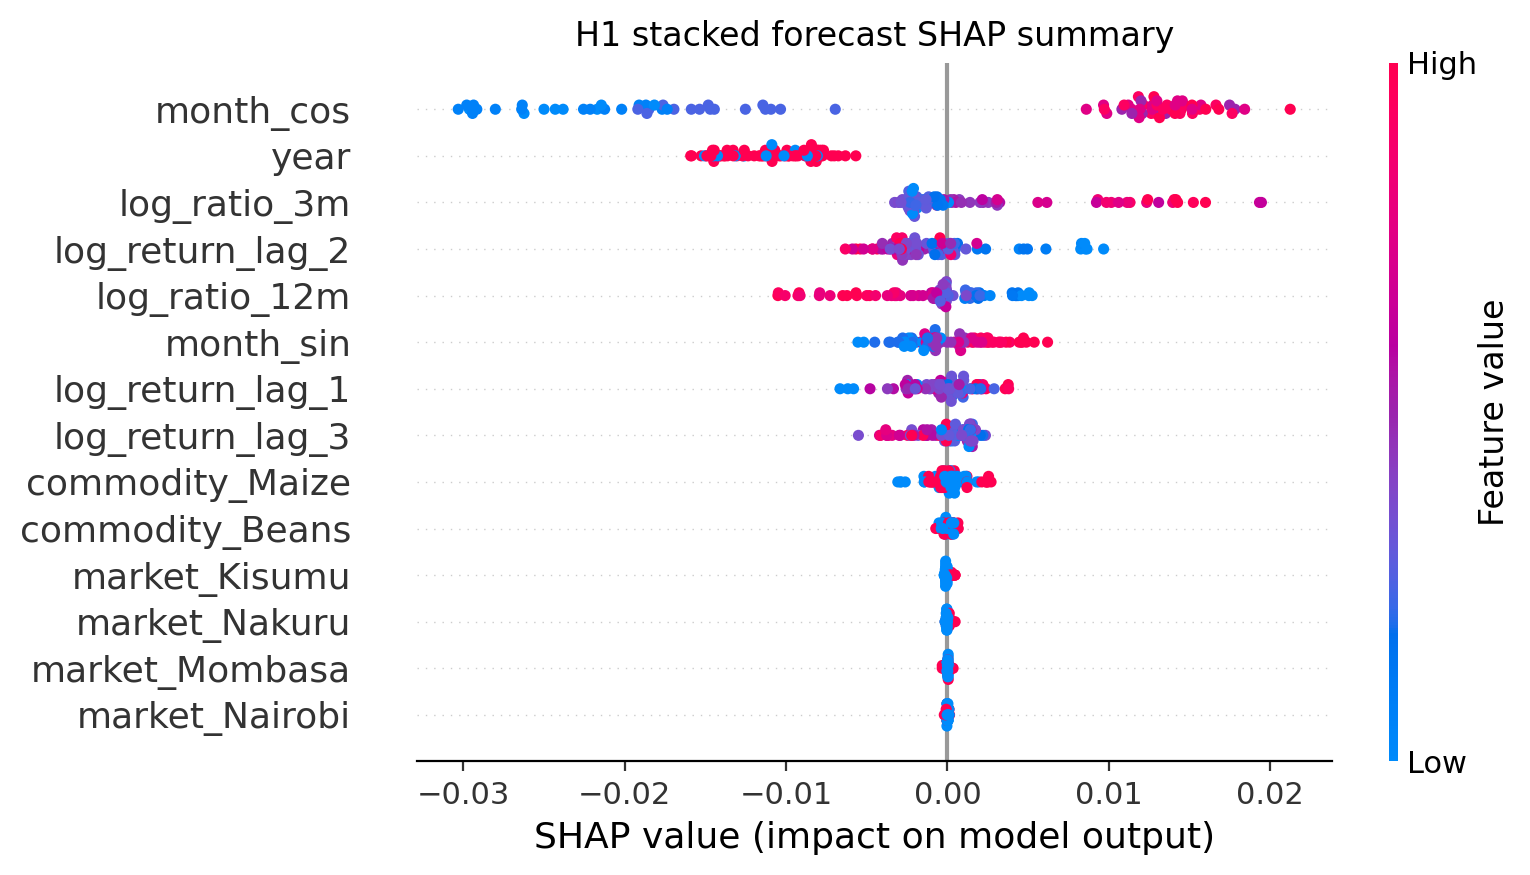

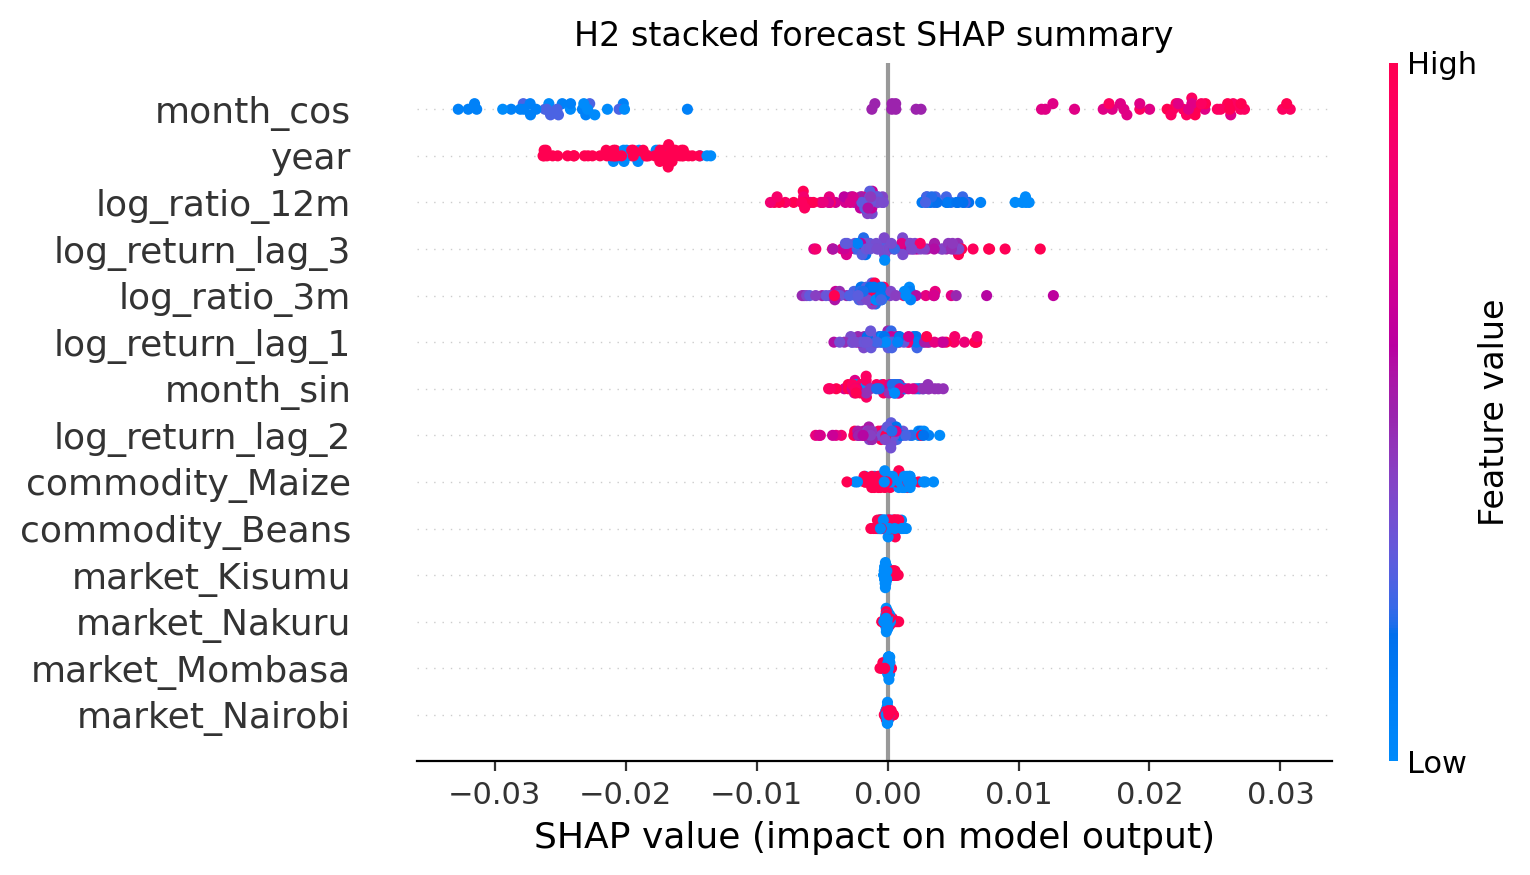

In [3]:
from IPython.display import Image, display

for horizon in ('h1', 'h2'):
    plot_path = shap_dir / f'shap_beeswarm_{horizon}.png'
    if not plot_path.exists():
        raise FileNotFoundError(f'{horizon.upper()} beeswarm plot was not saved: {plot_path}')
    display(Image(filename=str(plot_path), width=850))

<h3>4. Group Farmer-Facing Explanations</h3>

<p>This addendum groups the existing exact per-feature SHAP values into farmer-facing categories. It uses origin prices and stacking predictions from the saved final-evaluation prediction files and does not recompute base SHAP values, refit models, or rerun forecasts. Every held-out row is included; H1 and H2 have different eligible row counts.</p>

<p>Log contributions reconcile before display rounding. Percentage contributions are compounded approximations and are not additive. The output is structured data, not generated prose.</p>

In [4]:
grouped_explanations = {}
for horizon in ('h1', 'h2'):
    paths = horizon_paths[horizon]
    models = joblib.load(paths['model'])
    feature_cols = models['feature_cols']
    predictions = pd.read_csv(paths['predictions'], parse_dates=['month'])
    if not {'origin_price', 'stacking_pred'}.issubset(predictions.columns):
        raise ValueError(f'{horizon.upper()} predictions need origin_price and stacking_pred columns.')

    shap_paths = [shap_dir / f'shap_values_{horizon}.csv']
    if drive_shap_dir is not None:
        shap_paths.append(drive_shap_dir / f'shap_values_{horizon}.csv')
    shap_path = next((path for path in shap_paths if path.exists()), None)
    if shap_path is None:
        raise FileNotFoundError(f'Saved per-feature SHAP values are missing for {horizon.upper()}.')
    saved_shap = pd.read_csv(shap_path, parse_dates=['month'])
    required = {'horizon', 'base_value', *feature_cols, 'month', 'market', 'commodity'}
    missing = required.difference(saved_shap.columns)
    if missing:
        raise ValueError(f'{horizon.upper()} SHAP file is missing columns: {sorted(missing)}')
    if len(saved_shap) != len(predictions) or not saved_shap['horizon'].eq(horizon).all():
        raise ValueError(f'{horizon.upper()} saved SHAP rows do not match the predictions.')
    keys = ['month', 'market', 'commodity']
    if not saved_shap[keys].equals(predictions[keys]):
        raise ValueError(f'{horizon.upper()} SHAP rows and predictions are not aligned.')
    base_values = saved_shap['base_value'].to_numpy(dtype=float)
    if not np.isfinite(base_values).all() or not np.allclose(base_values, base_values[0]):
        raise ValueError(f'{horizon.upper()} SHAP base values are inconsistent.')
    shap_result = {
        'shap_values': saved_shap[feature_cols].to_numpy(dtype=float),
        'base_value': float(base_values[0]),
        'feature_names': feature_cols,
    }

    explanations = []
    reconciliation_errors = []
    for row_index, row in predictions.iterrows():
        explanation = shap_to_farmer_explanation(
            shap_result, row_index, float(row['origin_price']),
        )
        reconciliation_errors.append(
            abs(explanation['predicted_log_change'] - float(row['stacking_pred']))
        )
        explanations.append({
            'row_index': row_index,
            'month': row['month'].isoformat(),
            'market': row['market'],
            'commodity': row['commodity'],
            'stacking_prediction': float(row['stacking_pred']),
            **explanation,
        })

    max_error = max(reconciliation_errors, default=0.0)
    print(f'{horizon.upper()}: {len(explanations)} rows; maximum rounded-log reconciliation error={max_error:.6f}')
    labels = [group['label'] for group in explanations[0]['groups']]
    group_summary = sorted([
        {
            'label': label,
            'mean_abs_log_contribution': float(np.mean([
                abs(next(group['log_contribution'] for group in row['groups'] if group['label'] == label))
                for row in explanations
            ])),
        }
        for label in labels
    ], key=lambda item: item['mean_abs_log_contribution'], reverse=True)
    display(pd.DataFrame(group_summary))

    for row_index in sorted({0, len(explanations) // 2, len(explanations) - 1}):
        print(f'{horizon.upper()} full grouped explanation, row {row_index}:')
        print(json.dumps(explanations[row_index], indent=2, ensure_ascii=False))

    output = {
        'horizon': horizon,
        'test_rows': len(explanations),
        'max_abs_log_reconciliation_error_after_rounding': max_error,
        'group_mean_abs_log_contribution': group_summary,
        'explanations': explanations,
    }
    for output_dir in (shap_dir, drive_shap_dir):
        if output_dir is not None:
            output_dir.mkdir(parents=True, exist_ok=True)
            (output_dir / f'shap_grouped_{horizon}.json').write_text(
                json.dumps(output, indent=2, ensure_ascii=False), encoding='utf-8',
            )
            print(f'Saved {horizon.upper()} grouped JSON: {output_dir / f"shap_grouped_{horizon}.json"}')

H1: 88 rows; maximum rounded-log reconciliation error=0.000050


,label,mean_abs_log_contribution
0,Time of year,0.017235
1,Long-run trend,0.010912
2,Price compared with its recent average,0.004799
3,Recent price momentum,0.003293
4,Market and crop,0.001074


H1 full grouped explanation, row 0:
{
  "row_index": 0,
  "month": "2018-11-01T00:00:00",
  "market": "Kisumu",
  "commodity": "Beans",
  "stacking_prediction": -0.0095028190500862,
  "origin_price": 71.23,
  "predicted_price": 70.56,
  "predicted_log_change": -0.0095,
  "expected_change_pct": -0.95,
  "base_value": -0.0068,
  "groups": [
    {
      "label": "Long-run trend",
      "log_contribution": -0.0112,
      "pct_contribution": -1.12,
      "direction": "decreases"
    },
    {
      "label": "Time of year",
      "log_contribution": 0.0059,
      "pct_contribution": 0.59,
      "direction": "increases"
    },
    {
      "label": "Price compared with its recent average",
      "log_contribution": 0.0017,
      "pct_contribution": 0.17,
      "direction": "increases"
    },
    {
      "label": "Recent price momentum",
      "log_contribution": 0.0005,
      "pct_contribution": 0.05,
      "direction": "neutral"
    },
    {
      "label": "Market and crop",
      "log_contrib

,label,mean_abs_log_contribution
0,Time of year,0.022142
1,Long-run trend,0.019095
2,Price compared with its recent average,0.005366
3,Recent price momentum,0.003612
4,Market and crop,0.001638


H2 full grouped explanation, row 0:
{
  "row_index": 0,
  "month": "2018-11-01T00:00:00",
  "market": "Kisumu",
  "commodity": "Beans",
  "stacking_prediction": -0.0085527197816023,
  "origin_price": 71.23,
  "predicted_price": 70.62,
  "predicted_log_change": -0.0086,
  "expected_change_pct": -0.85,
  "base_value": -0.0086,
  "groups": [
    {
      "label": "Long-run trend",
      "log_contribution": -0.0191,
      "pct_contribution": -1.89,
      "direction": "decreases"
    },
    {
      "label": "Time of year",
      "log_contribution": 0.0156,
      "pct_contribution": 1.57,
      "direction": "increases"
    },
    {
      "label": "Recent price momentum",
      "log_contribution": 0.0056,
      "pct_contribution": 0.57,
      "direction": "increases"
    },
    {
      "label": "Price compared with its recent average",
      "log_contribution": -0.0025,
      "pct_contribution": -0.25,
      "direction": "decreases"
    },
    {
      "label": "Market and crop",
      "log_con